Semilinear fractional Laplacian on (-1,1)
s = 0.7500 | N = 100 | h = 1.980198e-02 | R = 10000

Running method: GL
Running method: PC
Running method: SP
Running method: PER
Running method: T
Running method: Q

Newton results
Weight Converged  Iter.    Residual       Linf error     Rel L2        
GL     true       4        2.03615e-13    2.54313e-02    1.35883e-02   
PC     true       4        1.12577e-13    6.95433e-02    3.22932e-02   
SP     true       4        2.73115e-13    1.58432e-02    5.33335e-03   
PER    true       4        1.27232e-13    7.34042e-03    3.02366e-03   
T      true       4        1.70752e-13    1.35372e-02    6.86538e-03   
Q      true       4        1.30118e-13    8.44336e-03    3.58924e-03   

Damped Picard results
Weight Converged  Iter.    Residual       Linf error     Rel L2        
GL     true       48       6.22515e-11    2.54313e-02    1.35883e-02   
PC     true       48       9.96512e-11    6.95433e-02    3.22932e-02   
SP     true       48       6.8059

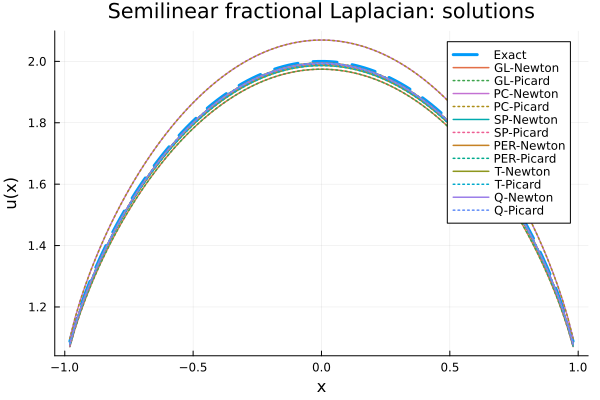

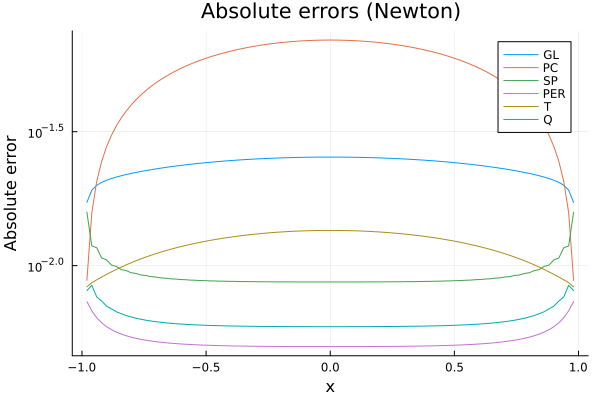


Plots saved as solutions_comparison.png and newton_errors.png.


In [1]:
# Semilinear fractional Laplacian on (-1,1)
# Compare GL, PC, SP, PER, T, and Q weights using Newton and Picard.
#
# Dependencies:
#   SpecialFunctions, HypergeometricFunctions, LinearAlgebra, Printf, Plots
#
# Run:
#   julia semilinear_fractional_laplacian.jl
#
# The discrete weights are truncated after R terms. For T and Q, s = 1/2
# requires separate logarithmic limiting formulas and is therefore rejected
# by this implementation.

using LinearAlgebra
using SpecialFunctions
using HypergeometricFunctions
using Printf
using Plots

# ----------------------------------------------------------------------
# Parameters
# ----------------------------------------------------------------------

const s = 0.75
const N = 100
const R = 10_000
const tol = 1.0e-10
const maxiter = 200
const omega_picard = 0.5
const methods = (:GL, :PC, :SP, :PER, :T, :Q)

const h = 2.0 / (N + 1)
const X = [-1.0 + j*h for j in 1:N]

# ----------------------------------------------------------------------
# Fractional Laplacian normalization and exact test problem
# ----------------------------------------------------------------------

"""
    C1(s)

Normalization in the singular-integral definition of (-Delta)^s in one
dimension:
C_{1,s} = 2^(2s) s Gamma(s+1/2)/(sqrt(pi) Gamma(1-s)).
"""
function C1(s::Real)
    0 < s < 1 || throw(ArgumentError("s must lie in (0,1)."))
    return 2.0^(2s) * s * gamma(s + 0.5) /
           (sqrt(pi) * gamma(1.0 - s))
end

"""
The function g(x)=(1-x^2)^s inside (-1,1), extended by zero outside.
"""
function g_exact(x::Real, s::Real)
    return abs(x) < 1.0 ? max(0.0, 1.0 - x^2)^s : 0.0
end

u_exact(x::Real, s::Real) = 1.0 + g_exact(x, s)

"""
For g(x)=(1-x^2)^s_+, (-Delta)^s g is constant on (-1,1):
kappa_s = 2^(2s) Gamma(s+1) Gamma(s+1/2)/sqrt(pi).
"""
function kappa(s::Real)
    0 < s < 1 || throw(ArgumentError("s must lie in (0,1)."))
    return 2.0^(2s) * gamma(s + 1.0) *
           gamma(s + 0.5) / sqrt(pi)
end

"""
Nonlinearity chosen so that u_exact(x)=1+(1-x^2)^s is a solution
of the continuous problem:
(-Delta)^s u = F(x,u), u=1 outside (-1,1).
"""
function F_nl(x::Real, u::Real, s::Real)
    g = g_exact(x, s)
    return kappa(s) * sqrt(abs(u)) / sqrt(1.0 + g)
end

function dF_du(x::Real, u::Real, s::Real)
    g = g_exact(x, s)
    abs(u) > 1.0e-14 ||
        throw(DomainError(u, "F_u is singular at u=0."))
    return kappa(s) * sign(u) /
           (2.0 * sqrt(abs(u)) * sqrt(1.0 + g))
end

# ----------------------------------------------------------------------
# Weight families
# ----------------------------------------------------------------------

# Piecewise-constant (PC) weights.
function w_PC(m::Integer, s::Real, h::Real)
    m >= 1 || throw(ArgumentError("m must be positive."))
    return C1(s) / (2.0*s*h^(2.0*s)) *
           ((m - 0.5)^(-2.0*s) - (m + 0.5)^(-2.0*s))
end

# Spectral (SP) weights; _1F_1 is evaluated by pFq.
function w_SP(m::Integer, s::Real, h::Real)
    m >= 1 || throw(ArgumentError("m must be positive."))
    return -h^(-2.0*s) * pi^(2.0*s) / (2.0*s + 1.0) *
           real(pFq((2.0*s + 1.0,), (2.0*s + 2.0,), im*m*pi))
end

# Periodic (PER) weights.
function w_PER(m::Integer, s::Real, h::Real)
    m >= 1 || throw(ArgumentError("m must be positive."))
    logw = -2.0*s*log(h) +
           loggamma(m - s) +
           loggamma(1.0 + 2.0*s) +
           log(sin(pi*s)) -
           log(pi) -
           loggamma(m + 1.0 + s)
    return exp(logw)
end

# Grunwald-Letnikov (GL) weights, computed using stable recurrences.
function make_weights_GL(R::Integer, s::Real, h::Real)
    R >= 1 || throw(ArgumentError("R must be positive."))
    0 < s < 1 || throw(ArgumentError("s must lie in (0,1)."))
    W = zeros(Float64, R)
    a = 2.0*s

    if isapprox(a, 1.0; atol=1e-12, rtol=0)
        for m in 1:R
            W[m] = 1.0 / (pi*h*m*(m + 1.0))
        end
        return W
    elseif a < 1.0
        W[1] = h^(-a) * a / (2.0*cos(pi*a/2.0))
        for m in 1:R-1
            W[m+1] = W[m] * (m-a)/(m+1.0)
        end
    else
        W[1] = -h^(-a) / (2.0*cos(pi*a/2.0)) *
               (1.0 + a*(a-1.0)/2.0)
        if R >= 2
            W[2] = h^(-a) * a*(1.0-a)*(2.0-a) /
                   (12.0*cos(pi*a/2.0))
            for m in 2:R-1
                W[m+1] = W[m] * (m+1.0-a)/(m+2.0)
            end
        end
    end
    return W
end

# Auxiliary functions for the T and Q quadrature weights.
function F_aux(t::Real, s::Real)
    abs(2.0*s - 1.0) > 1e-10 ||
        throw(ArgumentError("T/Q weights at s=1/2 need logarithmic limit formulas."))
    return t^(1.0 - 2.0*s) / ((2.0*s - 1.0)*(2.0*s))
end

function Fp_aux(t::Real, s::Real)
    return -t^(-2.0*s)/(2.0*s)
end

function G_aux(t::Real, s::Real)
    abs(2.0*s - 1.0) > 1e-10 ||
        throw(ArgumentError("T/Q weights at s=1/2 need logarithmic limit formulas."))
    return t^(2.0 - 2.0*s) /
           ((2.0 - 2.0*s)*(2.0*s - 1.0)*(2.0*s))
end

Gp_aux(t::Real, s::Real) = F_aux(t, s)
Gpp_aux(t::Real, s::Real) = Fp_aux(t, s)

# Tent / piecewise-linear quadrature (T) weights.
function w_T(m::Integer, s::Real, h::Real)
    m >= 1 || throw(ArgumentError("m must be positive."))
    abs(2.0*s - 1.0) > 1e-10 ||
        throw(ArgumentError("T weights at s=1/2 need logarithmic limit formulas."))
    if m == 1
        val = 1.0/(2.0 - 2.0*s) - Fp_aux(1.0, s) +
              F_aux(2.0, s) - F_aux(1.0, s)
    else
        val = F_aux(m + 1.0, s) - 2.0*F_aux(m, s) +
              F_aux(m - 1.0, s)
    end
    return C1(s) * h^(-2.0*s) * val
end

# Piecewise-quadratic quadrature (Q) weights.
function w_Q(m::Integer, s::Real, h::Real)
    m >= 1 || throw(ArgumentError("m must be positive."))
    abs(2.0*s - 1.0) > 1e-10 ||
        throw(ArgumentError("Q weights at s=1/2 need logarithmic limit formulas."))

    if m == 1
        val = 1.0/(2.0 - 2.0*s) - Gpp_aux(1.0, s) -
              (Gp_aux(3.0, s) + 3.0*Gp_aux(1.0, s))/2.0 +
              G_aux(3.0, s) - G_aux(1.0, s)
    elseif iseven(m)
        val = 2.0 * (Gp_aux(m + 1.0, s) + Gp_aux(m - 1.0, s) -
                     G_aux(m + 1.0, s) + G_aux(m - 1.0, s))
    else
        val = -(Gp_aux(m + 2.0, s) + 6.0*Gp_aux(m, s) +
                Gp_aux(m - 2.0, s))/2.0 +
              G_aux(m + 2.0, s) - G_aux(m - 2.0, s)
    end
    return C1(s) * h^(-2.0*s) * val
end

function make_weights(weight_function, R::Integer, s::Real, h::Real)
    W = Vector{Float64}(undef, R)
    @inbounds for m in 1:R
        W[m] = weight_function(m, s, h)
    end
    all(isfinite, W) ||
        throw(ErrorException("The selected method produced NaN or Inf weights."))
    return W
end

function select_weights(method::Symbol, R::Integer, s::Real, h::Real)
    if method === :GL
        return make_weights_GL(R, s, h)
    elseif method === :PC
        return make_weights(w_PC, R, s, h)
    elseif method === :SP
        return make_weights(w_SP, R, s, h)
    elseif method === :PER
        return make_weights(w_PER, R, s, h)
    elseif method === :T
        return make_weights(w_T, R, s, h)
    elseif method === :Q
        return make_weights(w_Q, R, s, h)
    else
        throw(ArgumentError("Unknown weight method: $method"))
    end
end

# ----------------------------------------------------------------------
# Discrete matrix and nonlinear system
# ----------------------------------------------------------------------

"""
Build the truncated discrete operator for zero exterior data.
The diagonal includes all retained weights; off-diagonal entries
use W[abs(i-j)] whenever the grid indices are distinct.
"""
function build_matrix(W::AbstractVector{<:Real}, N::Integer)
    A = zeros(Float64, N, N)
    diagonal_value = 2.0 * sum(W)
    Rloc = length(W)

    @inbounds for i in 1:N
        A[i, i] = diagonal_value
        for j in 1:N
            if i != j
                m = abs(i-j)
                if m <= Rloc
                    A[i, j] = -W[m]
                end
            end
        end
    end
    return A
end

function nonlinear_residual(V, A, X, s)
    Fvec = [F_nl(X[j], 1.0 + V[j], s) for j in eachindex(X)]
    return A*V - Fvec
end

residual_norm(V, A, X, s) = norm(nonlinear_residual(V, A, X, s), Inf)

# ----------------------------------------------------------------------
# Newton's method with backtracking
# ----------------------------------------------------------------------

function solve_newton(A, X, s; tol=1e-10, maxiter=200)
    V = zeros(Float64, length(X))

    for iter in 1:maxiter
        H = nonlinear_residual(V, A, X, s)
        res = norm(H, Inf)
        if res < tol
            return V, iter-1, res, true
        end

        U = 1.0 .+ V
        dF = [dF_du(X[j], U[j], s) for j in eachindex(X)]
        J = A - Diagonal(dF)
        delta = -(J \ H)

        alpha = 1.0
        accepted = false
        while alpha >= 1.0/1024.0
            Vtrial = V + alpha*delta
            if minimum(1.0 .+ Vtrial) > 1e-12
                rtrial = residual_norm(Vtrial, A, X, s)
                if isfinite(rtrial) && rtrial < res
                    V = Vtrial
                    accepted = true
                    break
                end
            end
            alpha /= 2.0
        end

        if !accepted
            return V, iter, res, false
        end
    end

    res = residual_norm(V, A, X, s)
    return V, maxiter, res, false
end

# ----------------------------------------------------------------------
# Damped Picard / fixed-point iteration
# ----------------------------------------------------------------------

function solve_picard(A, X, s; tol=1e-10, maxiter=200, omega=0.5)
    0.0 < omega <= 1.0 || throw(ArgumentError("omega must lie in (0,1]."))
    V = zeros(Float64, length(X))

    for iter in 1:maxiter
        Fvec = [F_nl(X[j], 1.0 + V[j], s) for j in eachindex(X)]
        Vpicard = A \ Fvec
        Vnew = (1.0-omega)*V + omega*Vpicard

        change = norm(Vnew - V, Inf)
        V = Vnew
        res = residual_norm(V, A, X, s)

        if change < tol && res < tol
            return V, iter, res, true
        end
    end

    res = residual_norm(V, A, X, s)
    return V, maxiter, res, false
end

# ----------------------------------------------------------------------
# Error measures and experiment driver
# ----------------------------------------------------------------------

function error_metrics(U, Uex, h)
    E = U .- Uex
    err_inf = norm(E, Inf)
    err_L2 = sqrt(h * sum(abs2, E))
    rel_inf = err_inf / max(norm(Uex, Inf), eps(Float64))
    rel_L2 = err_L2 / max(sqrt(h * sum(abs2, Uex)), eps(Float64))
    return err_inf, err_L2, rel_inf, rel_L2
end

function run_experiment(method::Symbol)
    W = select_weights(method, R, s, h)
    A = build_matrix(W, N)

    Vn, itn, rn, okn = solve_newton(A, X, s; tol=tol, maxiter=maxiter)
    Vp, itp, rp, okp = solve_picard(A, X, s; tol=tol,
                                    maxiter=maxiter, omega=omega_picard)

    Un = 1.0 .+ Vn
    Up = 1.0 .+ Vp
    Uex = [u_exact(x, s) for x in X]

    en = error_metrics(Un, Uex, h)
    ep = error_metrics(Up, Uex, h)

    return (method=method, W=W, A=A,
            Un=Un, Up=Up, Uex=Uex,
            itn=itn, rn=rn, okn=okn, en=en,
            itp=itp, rp=rp, okp=okp, ep=ep)
end

function main()
    println("Semilinear fractional Laplacian on (-1,1)")
    @printf("s = %.4f | N = %d | h = %.6e | R = %d\n\n", s, N, h, R)

    results = NamedTuple[]
    for method in methods
        println("Running method: ", method)
        push!(results, run_experiment(method))
    end

    println()
    println("Newton results")
    @printf("%-6s %-10s %-8s %-14s %-14s %-14s\n",
            "Weight", "Converged", "Iter.", "Residual", "Linf error", "Rel L2")
    for r in results
        @printf("%-6s %-10s %-8d %-14.5e %-14.5e %-14.5e\n",
                string(r.method), string(r.okn), r.itn, r.rn, r.en[1], r.en[4])
    end

    println()
    println("Damped Picard results")
    @printf("%-6s %-10s %-8s %-14s %-14s %-14s\n",
            "Weight", "Converged", "Iter.", "Residual", "Linf error", "Rel L2")
    for r in results
        @printf("%-6s %-10s %-8d %-14.5e %-14.5e %-14.5e\n",
                string(r.method), string(r.okp), r.itp, r.rp, r.ep[1], r.ep[4])
    end

    # Solution plot: exact solution and both iterative solutions for each weight.
    p1 = plot(X, results[1].Uex, label="Exact", linewidth=3,
              linestyle=:dash, xlabel="x", ylabel="u(x)",
              title="Semilinear fractional Laplacian: solutions")
    for r in results
        plot!(p1, X, r.Un, label="$(r.method)-Newton", linewidth=1.5)
        plot!(p1, X, r.Up, label="$(r.method)-Picard", linewidth=1.5,
              linestyle=:dot)
    end
    savefig(p1, "solutions_comparison.png")
    display(p1)

    # Absolute errors for Newton's method.
    p2 = plot(X, max.(abs.(results[1].Un .- results[1].Uex), eps(Float64)),
              yscale=:log10, label=string(results[1].method),
              xlabel="x", ylabel="Absolute error",
              title="Absolute errors (Newton)")
    for r in results[2:end]
        plot!(p2, X, max.(abs.(r.Un .- r.Uex), eps(Float64)),
              label=string(r.method))
    end
    savefig(p2, "newton_errors.png")
    display(p2)

    println("\nPlots saved as solutions_comparison.png and newton_errors.png.")
end

main()